In [1]:
from __future__ import annotations

import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

np.set_printoptions(precision=10, suppress=False, threshold=2000)


def find_project_root(start: Path | None = None) -> Path:
    start = Path.cwd() if start is None else Path(start).resolve()
    for path in [start, *start.parents]:
        if (path / "codes").is_dir() and (path / "gfn2-xtb.toml").exists():
            return path
    raise RuntimeError("Could not find project root. Run this notebook inside optxTB-MD or set PROJECT_ROOT_PATH manually.")


PROJECT_ROOT_PATH = find_project_root()
PROJECT_ROOT = str(PROJECT_ROOT_PATH)
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

print("PROJECT_ROOT_PATH:", PROJECT_ROOT_PATH)

from codes.calculate_ae_charged import vector_to_param_changes
from codes.gradients import ensure_param_file

PROJECT_ROOT_PATH: /dss/dsshome1/09/ge45fol2/cluster_vs_pbc/optxTB-MD


In [2]:
OPTIMIZATION_RUN_ID = 'nsga3_t2na_t3_efq_na_reg_216898_20260806_174242' # (E, F, HI) for H/O 249
#OPTIMIZATION_RUN_ID = 'nsga3_t2na_t3_efq_na_reg_216899_20260809_183219' # (E, F, CM5) for H/O 249

RUN_OUTPUT_DIR = PROJECT_ROOT_PATH / "optimization/T_all_partial_charge_schemes/hpc_runs" / OPTIMIZATION_RUN_ID

if OPTIMIZATION_RUN_ID == "nsga3_t2na_t3_efq_na_reg_216898_20260806_174242":
    point = 249
    type_charge = "hirshfeldI"
    print(f'Processing H/O point {point} and charge scheme {type_charge}')
    results_path = RUN_OUTPUT_DIR / f"nsga3_results_cluster_na_EFQ_{OPTIMIZATION_RUN_ID}.npz"
elif OPTIMIZATION_RUN_ID == "nsga3_t2na_t3_efq_na_reg_216899_20260809_183219":
    point = 249
    type_charge = "CM5"
    print(f'Processing H/O point {point} and charge scheme {type_charge}')
    results_path = RUN_OUTPUT_DIR / f"nsga3_results_cluster_na_EFQ_{OPTIMIZATION_RUN_ID}.npz"

if not results_path.exists():
    results_path = sorted(RUN_OUTPUT_DIR.glob("nsga3_results_cluster_na_EFQReg_*.npz"))[0]

print(results_path)

Processing H/O point 249 and charge scheme hirshfeldI
/dss/dsshome1/09/ge45fol2/cluster_vs_pbc/optxTB-MD/optimization/T_all_partial_charge_schemes/hpc_runs/nsga3_t2na_t3_efq_na_reg_216898_20260806_174242/nsga3_results_cluster_na_EFQReg_nsga3_t2na_t3_efq_na_reg_216898_20260806_174242.npz


In [3]:
base_param_file = PROJECT_ROOT_PATH / "gfn2-xtb.toml"

print(f"Selected partial charge scheme: {type_charge}")

Selected partial charge scheme: hirshfeldI


In [4]:
param_changes = {
    "kpair": {
        "Na-O": 1.0,
        "Na-H": 1.0,
    },
    "Na": {
        "slater": [0.7637870000000000, 0.5735530000000000],
        "gam": 0.2710560000000000,
        "zeff": 5.2449170000000001,
        "arep": 0.5727280000000000,
    },
}

def generate_parameter_info(param_changes, variation=0.30, kernel_abs=0.03, near_one_width=0.20, positivity_eps=1e-12, fallback_zero_abs=0.20, fixed_components=None):
    if fixed_components is None:
        fixed_components = set()

    def _percent_box(val):
        if val == 0:
            return [-fallback_zero_abs, +fallback_zero_abs]
        lo = min(val * (1 - variation), val * (1 + variation))
        hi = max(val * (1 - variation), val * (1 + variation))
        return [lo, hi]

    def _near_one_box():
        return [max(positivity_eps, 1.0 - near_one_width), 1.0 + near_one_width]

    def _make_bound(elem, key, val, idx=None):
        if key == "dkernel" and elem == "Na":
            lo, hi = -abs(kernel_abs), abs(kernel_abs)
        elif key in {"Na-O", "Na-H", "Cl-H", "Cl-O", "H-H", "O-O", "O-H"}:
            lo, hi = _near_one_box()
        elif key == "gam":
            lo, hi = _percent_box(val)
            lo = max(lo, positivity_eps)
        else:
            lo, hi = _percent_box(val)

        if not (hi > lo):
            mid = 0.5 * (lo + hi)
            tiny = max(1e-9, abs(mid) * 1e-12)
            lo, hi = mid - tiny, mid + tiny
        return [lo, hi]

    names = []
    bounds = []
    vector = []
    structure = {}
    for elem, params in param_changes.items():
        structure[elem] = {}
        for key, value in params.items():
            if isinstance(value, list):
                structure[elem][key] = []
                for i, val in enumerate(value):
                    if key == "lgam" and i == 0:
                        structure[elem][key].append("Fixing to 1.0")
                        continue
                    if (elem, key, i) in fixed_components:
                        structure[elem][key].append(("__fixed__", val))
                        continue
                    par_name = f"{elem}_{key}_{i}"
                    names.append(par_name)
                    bounds.append(_make_bound(elem, key, val, idx=i))
                    vector.append(val)
                    structure[elem][key].append(par_name)
            else:
                par_name = f"{elem}_{key}"
                names.append(par_name)
                bounds.append(_make_bound(elem, key, value))
                vector.append(value)
                structure[elem][key] = par_name
    return names, bounds, vector, structure


names, bounds, default_gfn2_vector, structure = generate_parameter_info(
    param_changes,
    fixed_components={("Na", "slater", 1)}
)
default_gfn2_vector = np.asarray(default_gfn2_vector, dtype=float)
print(names)
print(default_gfn2_vector)

['kpair_Na-O', 'kpair_Na-H', 'Na_slater_0', 'Na_gam', 'Na_zeff', 'Na_arep']
[1.       1.       0.763787 0.271056 5.244917 0.572728]


In [5]:
with np.load(results_path) as data:
    X_pareto = data["X_pareto"]
    F_pareto = data["F_pareto"]

print("X_pareto shape:", X_pareto.shape)
print("F_pareto shape:", F_pareto.shape)

X_pareto shape: (90, 6)
F_pareto shape: (90, 4)


Number of Pareto points better than GFN2-xTB: 18


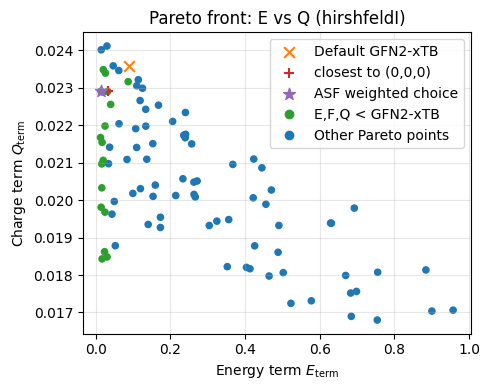

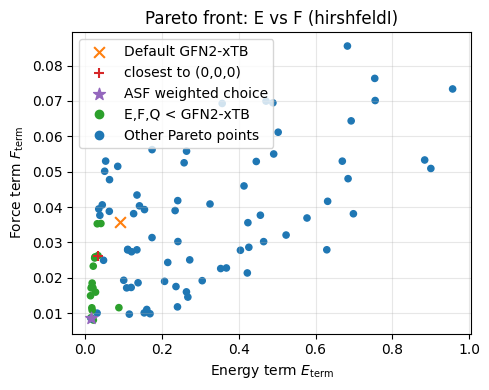

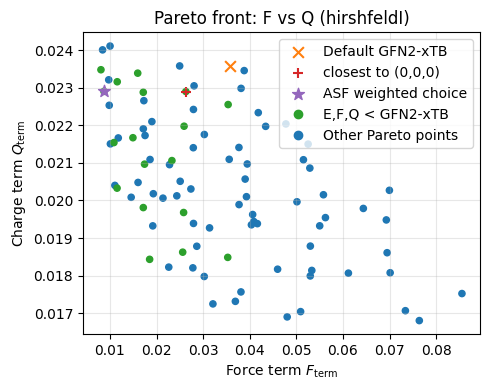

knee_selected_idx: 56
knee_objectives: [0.0326232334 0.0262998368 0.0229045186 0.0974535637]
knee_params: [0.9803243155 1.0811858673 0.6444885003 0.273653579  5.445103969
 0.5127176973]

asf_selected_idx: 17
asf_objectives: [0.014100347  0.0087203868 0.0229095041 0.497267801 ]
asf_objectives / default: [0.1588224469 0.2439829072 0.9713989763]
asf_weights [E, F, Q]: [0.5 0.5 0. ]
asf_value: 0.00902032690902332
asf_params: [0.9790029347 1.0450888763 0.5400569281 0.1902017913 5.1663739257
 0.4028759124]


In [6]:
from matplotlib.lines import Line2D
E_term = F_pareto[:, 0]
F_term = F_pareto[:, 1]
Q_term = F_pareto[:, 2]
Reg_term = F_pareto[:, 3]

if OPTIMIZATION_RUN_ID == 'nsga3_t2na_t3_efq_na_reg_216898_20260806_174242': # (E, F, HI) for H/O 249
    # dE: 0.0887805676, dF: 0.0357417941, dQ: 0.0235840315
    E0 = 0.0887805676
    F0 = 0.0357417941
    Q0 = 0.0235840315
elif OPTIMIZATION_RUN_ID == 'nsga3_t2na_t3_efq_na_reg_216899_20260809_183219': # (E, F, CM5) for H/O 249
    # dE: 0.0887805676, dF: 0.0357417941, dQ: 0.0395589955
    E0 = 0.0887805676
    F0 = 0.0357417941
    Q0 = 0.0395589955

better_mask = (
    (E_term <= E0) &
    (F_term <= F0) &
    (Q_term <= Q0) &
    ((E_term < E0) | (F_term < F0) | (Q_term < Q0))
)

F_better = F_pareto[better_mask]
X_better = X_pareto[better_mask]

if len(F_better) == 0:
    raise ValueError("No Pareto points better than GFN2-xTB in all three objectives.")

dist2 = np.sum(F_better**2, axis=1)  # расстояние^2 до (0,0,0)
print(f'Number of Pareto points better than GFN2-xTB: {len(F_better)}')

knee_idx = np.argmin(dist2)
knee_params = X_better[knee_idx]
knee_objectives = F_better[knee_idx]
knee_selected_idx = np.where(better_mask)[0][knee_idx]


# ----------------------- ASF selection ----------------------- #
# Energy must improve / not worsen relative to default.
# Then ASF chooses a weighted compromise.
# Larger weights below mean "more important" in this implementation.
# Here: forces are most important, virials second, energies third.

mask = (
    (E_term <= E0) &
    (F_term <= F0) &
    (Q_term <= Q0) &
    ((E_term < E0) | (F_term < F0) | (Q_term < Q0))
)

if Reg_term is not None:
    # 2. Регуляризация как constraint.
    # Если ты считаешь, что все Reg значения терпимые, оставь np.inf.
    R_max = np.inf


    mask = mask & (Reg_term <= R_max)

F_cand = F_pareto[mask]
X_cand = X_pareto[mask]
idx_cand = np.flatnonzero(mask)

if len(F_cand) == 0:
    raise ValueError("No candidates after E/Reg filtering.")

# 3. ASF только для E и F
weights = np.array([0.5, 0.5, 0.0])  # E, F, Q
weights = weights / weights.sum()

F_norm = F_cand[:, :3] / np.array([E0, F0, Q0])

ideal = np.min(F_norm, axis=0)

rho = 1e-6
delta = F_norm - ideal

asf_values = (
    np.max(weights * delta, axis=1)
    + rho * np.sum(weights * delta, axis=1)
)

j = np.argmin(asf_values)

asf_selected_idx = idx_cand[j]
asf_params = X_cand[j]
asf_objectives = F_cand[j]


colors = np.where(
    np.where(F_pareto[:, 0] < E0, True, False) *
    np.where(F_pareto[:, 1] < F0, True, False) *
    np.where(F_pareto[:, 2] < Q0, True, False) == True,
    'tab:green',
    'tab:blue'
)

green_proxy = Line2D([0], [0], marker='o', linestyle='', color='tab:green', label='E,F,Q < GFN2')
blue_proxy = Line2D([0], [0], marker='o', linestyle='', color='tab:blue', label='Other Pareto points')


plt.figure(figsize=(5, 4))
plt.scatter(E_term, Q_term, s=20, c=colors, label="_nolegend_")
plt.scatter([E0], [Q0], s=60, marker="x", c='tab:orange', label="Default GFN2-xTB")
plt.scatter([knee_objectives[0]], [knee_objectives[2]], s=60, marker="+", c='tab:red', label="closest to (0,0,0)")
plt.scatter([asf_objectives[0]], [asf_objectives[2]], s=80, marker="*", c='tab:purple', label="ASF weighted choice")
plt.xlabel("Energy term $E_{\\text{term}}$")
plt.ylabel("Charge term $Q_{\\text{term}}$")
plt.title(f"Pareto front: E vs Q ({type_charge})")
plt.grid(True, alpha=0.3)
ax = plt.gca()
handles, labels = ax.get_legend_handles_labels()
handles.extend([green_proxy, blue_proxy])
labels.extend(['E,F,Q < GFN2-xTB', 'Other Pareto points'])
plt.legend(handles, labels)
plt.tight_layout()
plt.show()


plt.figure(figsize=(5, 4))
plt.scatter(E_term, F_term, s=20, c=colors, label="_nolegend_")
plt.scatter([E0], [F0], s=60, marker="x", c='tab:orange', label="Default GFN2-xTB")
plt.scatter([knee_objectives[0]], [knee_objectives[1]], s=60, marker="+", c='tab:red', label="closest to (0,0,0)")
plt.scatter([asf_objectives[0]], [asf_objectives[1]], s=80, marker="*", c='tab:purple', label="ASF weighted choice")
plt.xlabel("Energy term $E_{\\text{term}}$")
plt.ylabel("Force term $F_{\\text{term}}$")
plt.title(f"Pareto front: E vs F ({type_charge})")
plt.grid(True, alpha=0.3)
ax = plt.gca()
handles, labels = ax.get_legend_handles_labels()
handles.extend([green_proxy, blue_proxy])
labels.extend(['E,F,Q < GFN2-xTB', 'Other Pareto points'])
plt.legend(handles, labels)
plt.tight_layout()
plt.show()


plt.figure(figsize=(5, 4))
plt.scatter(F_term, Q_term, s=20, c=colors, label="_nolegend_")
plt.scatter([F0], [Q0], s=60, marker="x", c='tab:orange', label="Default GFN2-xTB")
plt.scatter([knee_objectives[1]], [knee_objectives[2]], s=60, marker="+", c='tab:red', label="closest to (0,0,0)")
plt.scatter([asf_objectives[1]], [asf_objectives[2]], s=80, marker="*", c='tab:purple', label="ASF weighted choice")
plt.xlabel("Force term $F_{\\text{term}}$")
plt.ylabel("Charge term $Q_{\\text{term}}$")
plt.title(f"Pareto front: F vs Q ({type_charge})")
plt.grid(True, alpha=0.3)
ax = plt.gca()
handles, labels = ax.get_legend_handles_labels()
handles.extend([green_proxy, blue_proxy])
labels.extend(['E,F,Q < GFN2-xTB', 'Other Pareto points'])
plt.legend(handles, labels)
plt.tight_layout()
plt.show()


print("knee_selected_idx:", knee_selected_idx)
print("knee_objectives:", knee_objectives)
print("knee_params:", knee_params)

print()
print("asf_selected_idx:", asf_selected_idx)
print("asf_objectives:", asf_objectives)
print("asf_objectives / default:", asf_objectives[:3] / np.array([E0, F0, Q0]))
print("asf_weights [E, F, Q]:", weights)
print("asf_value:", asf_values[j])
print("asf_params:", asf_params)

In [7]:
# sorting by Regularization, filtering arep by not more then - 25% diff:
arep_idx = -1

# Оставляем точки, где arep уменьшился не более чем на 25%
idx_cand_filtered = [
    i for i in idx_cand
    if (
        (X_pareto[i, arep_idx] - default_gfn2_vector[arep_idx])
        / default_gfn2_vector[arep_idx]
        * 100
    ) >= -30
]

# Сортируем по Reg: от меньшего к большему
idx_cand_sorted = sorted(
    idx_cand_filtered,
    key=lambda i: F_pareto[i, 3],
)

for i in idx_cand_sorted:
    delta_percent = (
        (X_pareto[i] - default_gfn2_vector)
        / default_gfn2_vector
        * 100
    )

    print(
        f"Pareto point {i}: "
        f"E={F_pareto[i, 0]:.6f}, "
        f"F={F_pareto[i, 1]:.6f}, "
        f"Q={F_pareto[i, 2]:.6f}, "
        f"Reg={F_pareto[i, 3]:.6f}"
    )
    print(
        f"Objectives / default: "
        f"E={F_pareto[i, 0] / E0:.6f}, "
        f"F={F_pareto[i, 1] / F0:.6f}, "
        f"Q={F_pareto[i, 2] / Q0:.6f}, "
    )
    print(f"Parameters: {X_pareto[i].tolist()}")
    print(f"Changes (%): {delta_percent}")
    print(f"arep change: {delta_percent[-1]:.2f}%")
    print()

Pareto point 56: E=0.032623, F=0.026300, Q=0.022905, Reg=0.097454
Objectives / default: E=0.367459, F=0.735829, Q=0.971188, 
Parameters: [0.9803243154898033, 1.0811858672944055, 0.6444885003143959, 0.2736535790446055, 5.445103968984307, 0.5127176972906673]
Changes (%): [ -1.967568451    8.1185867294 -15.6193414768   0.9583182238
   3.816780494  -10.4779760566]
arep change: -10.48%

Pareto point 61: E=0.026234, F=0.015966, Q=0.023394, Reg=0.103925
Objectives / default: E=0.295497, F=0.446695, Q=0.991936, 
Parameters: [0.9773356719555054, 1.05756904085011, 0.6916415668695131, 0.25269689627751923, 5.364334478030617, 0.46793499117966486]
Changes (%): [ -2.2664328044   5.756904085   -9.4457529561  -6.773177396
   2.2768230275 -18.2971687817]
arep change: -18.30%

Pareto point 36: E=0.040291, F=0.035364, Q=0.022557, Reg=0.105212
Objectives / default: E=0.453830, F=0.989420, Q=0.956444, 
Parameters: [0.9805740059585211, 1.1447620531412392, 0.7084883986833643, 0.2561870357133267, 5.31344266809

In [8]:
if type_charge == "CM5":
    # ============================================================
    # Slater exponent screening of Pareto solutions for CM5
    # ============================================================
    slater_idx = 2
    reg_idx = 3
    # purely a visual guide:
    # "close to the default Slater exponent"
    slater_near_default = 5.0  # %

    # Sort the already filtered candidates by regularization
    idx_sorted = sorted(
        idx_cand_filtered,
        key=lambda i: F_pareto[i, reg_idx],
    )

    # Collect values
    regs = np.array([
        F_pareto[i, reg_idx]
        for i in idx_sorted
    ])

    slater_changes = np.array([
        (
            X_pareto[i, slater_idx]
            / default_gfn2_vector[slater_idx]
            - 1.0
        ) * 100
        for i in idx_sorted
    ])


    # First solution by regularization
    first_reg = idx_sorted[0]

    print("Lowest-Reg point:", first_reg)


    # ============================================================
    # Plot
    # ============================================================

    fig, ax = plt.subplots(figsize=(6.4, 3.6))

    # ±5% region around default
    ax.axhspan(
        -slater_near_default,
        slater_near_default,
        color="0.92",
        zorder=0,
        label=r"CM5 front: $|\Delta \text{Na_slater_0}| \leq 5\%$"
    )

    # Default
    ax.axhline(
        0,
        color="black",
        lw=1.1,
        ls="--",
    )

    # Connect points in increasing-Reg order
    ax.plot(
        regs,
        slater_changes,
        color="0.70",
        lw=1.0,
        zorder=1,
    )

    # All candidates
    ax.scatter(
        regs,
        slater_changes,
        s=42,
        facecolor="white",
        edgecolor="0.35",
        linewidth=1.0,
        zorder=2,
    )


    # ============================================================
    # Labels for every point
    # ============================================================

    for x, y, i in zip(regs, slater_changes, idx_sorted):
        ax.annotate(
            str(i),
            (x, y),
            xytext=(4, 4),
            textcoords="offset points",
            fontsize=8,
            color="0.35",
        )


    # ============================================================
    # Highlight point 2
    # ============================================================

    i_bad = 2

    x_bad = F_pareto[i_bad, reg_idx]
    y_bad = (
        X_pareto[i_bad, slater_idx]
        / default_gfn2_vector[slater_idx]
        - 1
    ) * 100

    ax.scatter(
        x_bad,
        y_bad,
        s=90,
        color="tab:green",
        edgecolor="black",
        linewidth=0.8,
        zorder=5,
    )


    # ============================================================
    # Formatting
    # ============================================================

    ax.set_xlabel("Regularization")
    ax.set_ylabel(
        r"Change in $\text{Na_slater_0}$ (%)"
    )

    ax.grid(
        alpha=0.18,
        linewidth=0.6,
    )

    ax.legend(
        frameon=False,
        fontsize=9,
        loc="lower right",
    )

    plt.tight_layout()
    plt.show()

Lowest-Reg point: 56
First near-default Slater point: 89


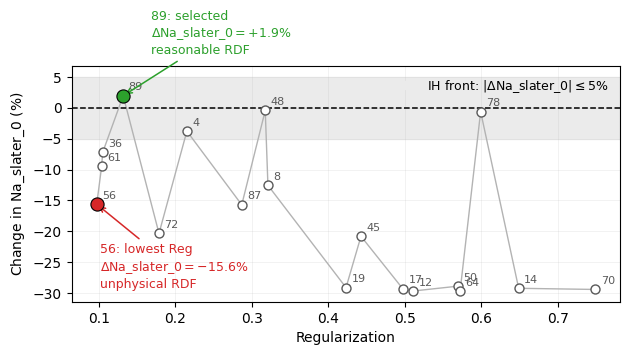

In [9]:
if type_charge == "hirshfeldI":
    # ============================================================
    # Slater exponent screening of Pareto solutions
    # ============================================================
    slater_idx = 2
    reg_idx = 3
    # purely a visual guide:
    # "close to the default Slater exponent"
    slater_near_default = 5.0  # %

    # Sort the already filtered candidates by regularization
    idx_sorted = sorted(
        idx_cand_filtered,
        key=lambda i: F_pareto[i, reg_idx],
    )

    # Collect values
    regs = np.array([
        F_pareto[i, reg_idx]
        for i in idx_sorted
    ])

    slater_changes = np.array([
        (
            X_pareto[i, slater_idx]
            / default_gfn2_vector[slater_idx]
            - 1.0
        ) * 100
        for i in idx_sorted
    ])


    # First solution by regularization
    first_reg = idx_sorted[0]

    # First solution whose Slater exponent is within ±5% of default
    first_near_default = next(
        i for i in idx_sorted
        if abs(
            (
                X_pareto[i, slater_idx]
                / default_gfn2_vector[slater_idx]
                - 1.0
            ) * 100
        ) <= slater_near_default
    )

    print("Lowest-Reg point:", first_reg)
    print("First near-default Slater point:", first_near_default)


    # ============================================================
    # Plot
    # ============================================================

    fig, ax = plt.subplots(figsize=(6.4, 3.6))

    # ±5% region around default
    ax.axhspan(
        -slater_near_default,
        slater_near_default,
        color="0.92",
        zorder=0,
        label=r"IH front: $|\Delta \text{Na_slater_0}| \leq 5\%$"
    )

    # Default
    ax.axhline(
        0,
        color="black",
        lw=1.1,
        ls="--",
    )

    # Connect points in increasing-Reg order
    ax.plot(
        regs,
        slater_changes,
        color="0.70",
        lw=1.0,
        zorder=1,
    )

    # All candidates
    ax.scatter(
        regs,
        slater_changes,
        s=42,
        facecolor="white",
        edgecolor="0.35",
        linewidth=1.0,
        zorder=2,
    )


    # ============================================================
    # Labels for every point
    # ============================================================

    for x, y, i in zip(regs, slater_changes, idx_sorted):
        ax.annotate(
            str(i),
            (x, y),
            xytext=(4, 4),
            textcoords="offset points",
            fontsize=8,
            color="0.35",
        )


    # ============================================================
    # Highlight point 56
    # ============================================================

    i_bad = 56

    x_bad = F_pareto[i_bad, reg_idx]
    y_bad = (
        X_pareto[i_bad, slater_idx]
        / default_gfn2_vector[slater_idx]
        - 1
    ) * 100

    ax.scatter(
        x_bad,
        y_bad,
        s=90,
        color="tab:red",
        edgecolor="black",
        linewidth=0.8,
        zorder=5,
    )

    ax.annotate(
        "56: lowest Reg\n"
        r"$\Delta \text{Na_slater_0}=-15.6\%$"
        "\nunphysical RDF",
        xy=(x_bad, y_bad),
        xytext=(2, -60),
        textcoords="offset points",
        fontsize=9,
        color="tab:red",
        arrowprops=dict(
            arrowstyle="->",
            color="tab:red",
            lw=1.1,
        ),
    )


    # ============================================================
    # Highlight point 89
    # ============================================================

    i_good = 89

    x_good = F_pareto[i_good, reg_idx]
    y_good = (
        X_pareto[i_good, slater_idx]
        / default_gfn2_vector[slater_idx]
        - 1
    ) * 100

    ax.scatter(
        x_good,
        y_good,
        s=90,
        color="tab:green",
        edgecolor="black",
        linewidth=0.8,
        zorder=5,
    )

    ax.annotate(
        "89: selected\n"
        r"$\Delta\text{Na_slater_0}=+1.9\%$"
        "\nreasonable RDF",
        xy=(x_good, y_good),
        xytext=(20, 30),
        textcoords="offset points",
        fontsize=9,
        color="tab:green",
        arrowprops=dict(
            arrowstyle="->",
            color="tab:green",
            lw=1.1,
        ),
    )


    # ============================================================
    # Formatting
    # ============================================================

    ax.set_xlabel("Regularization")
    ax.set_ylabel(
        r"Change in $\text{Na_slater_0}$ (%)"
    )

    ax.grid(
        alpha=0.18,
        linewidth=0.6,
    )

    ax.legend(
        frameon=False,
        fontsize=9,
        loc="upper right",
    )

    plt.tight_layout()
    plt.show()

In [ ]:
import toml

FIXED_HO_TOML_PATH = PROJECT_ROOT_PATH / "parameter_files/nsga3_EF_water_full_reg_6_params_249.toml"
FIXED_ELEMENT_PARAMS = {
    "H": ("zeff", "arep"),
    "O": ("zeff", "arep"),
}
FIXED_KPAIR_KEYS = ("O-O", "O-H")

def load_fixed_params_from_toml(path, fixed_element_params, fixed_kpair_keys):
    params = toml.load(path)
    fixed = {"kpair": {}}
    kpair = params["hamiltonian"]["xtb"]["kpair"]
    for key in fixed_kpair_keys:
        fixed["kpair"][key] = kpair[key]
    for elem, keys in fixed_element_params.items():
        fixed[elem] = {}
        elem_params = params["element"][elem]
        for key in keys:
            fixed[elem][key] = elem_params[key]
    return fixed

def merge_param_changes(fixed_changes, optimized_changes):
    merged = {}
    for elem, params in fixed_changes.items():
        merged[elem] = {key: list(val) if isinstance(val, list) else val for key, val in params.items()}
    for elem, params in optimized_changes.items():
        merged.setdefault(elem, {})
        for key, val in params.items():
            merged[elem][key] = list(val) if isinstance(val, list) else val
    return merged

fixed_param_changes = load_fixed_params_from_toml(FIXED_HO_TOML_PATH, FIXED_ELEMENT_PARAMS, FIXED_KPAIR_KEYS)

def save_param_toml(vector, out_dir, name):
    optimized_changes = vector_to_param_changes(vector, structure)
    param_dict = merge_param_changes(fixed_param_changes, optimized_changes)
    path_to_save = ensure_param_file(param_dict, param_file=str(base_param_file), DIR=out_dir)
    #rename the file
    os.rename(path_to_save, os.path.join(out_dir, f"{name}.toml"))
    print(f'Saved file to {path_to_save}')

if type_charge == "hirshfeldI":
    manual_selection_idx = 89
elif type_charge == "CM5":
    manual_selection_idx = 2
manual_selection_params = X_pareto[manual_selection_idx]

save_param_toml(manual_selection_params, str(PROJECT_ROOT_PATH / "parameter_files"), f'nsga3_EFQ_Na_reg_full_{point}_{manual_selection_idx}_{type_charge}')

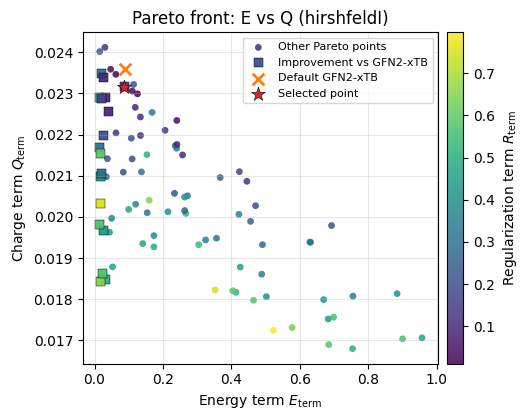

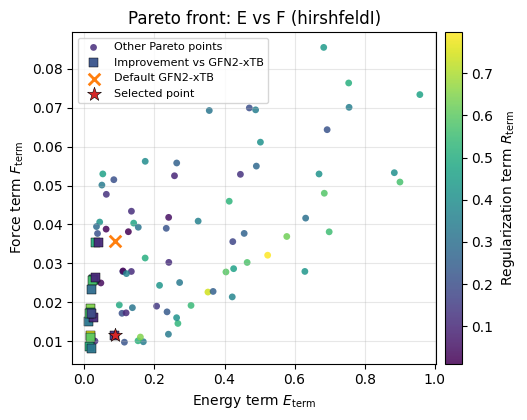

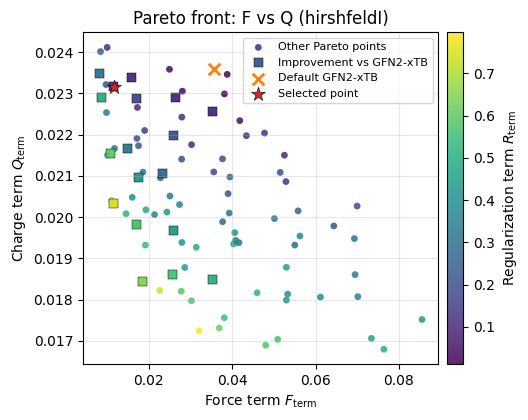

In [13]:
from matplotlib.colors import Normalize
from matplotlib.lines import Line2D

# ----------------------- Plot styling ----------------------- #

# Improvement marker:
# здесь я использую твой better_mask:
# E,F,Q не хуже default, и хотя бы одна цель лучше.
improvement_mask = better_mask
other_mask = ~improvement_mask

# Color encodes regularization.
# Можно заменить "magma" на "viridis", "plasma", "cividis".
reg_cmap = "viridis"

reg_norm = Normalize(
    vmin=np.nanmin(Reg_term),
    vmax=np.nanmax(Reg_term),
)


def plot_pareto_with_reg_heatmap(
    x, y,
    x0, y0,
    asf_x, asf_y,
    xlabel, ylabel, title,
):
    fig, ax = plt.subplots(figsize=(5.4, 4.3))

    # Other Pareto points: circles
    sc = ax.scatter(
        x[other_mask],
        y[other_mask],
        c=Reg_term[other_mask],
        cmap=reg_cmap,
        norm=reg_norm,
        s=24,
        marker="o",
        alpha=0.85,
        edgecolors="none",
        label="Other Pareto points",
    )

    # Improved solutions: squares
    ax.scatter(
        x[improvement_mask],
        y[improvement_mask],
        c=Reg_term[improvement_mask],
        cmap=reg_cmap,
        norm=reg_norm,
        s=42,
        marker="s",
        alpha=0.95,
        edgecolors="black",
        linewidths=0.35,
        label=r"Improvement vs GFN2-xTB",
    )

    # Reference / selected points
    ax.scatter(
        [x0], [y0],
        s=70,
        marker="x",
        c="tab:orange",
        linewidths=2.0,
        label="Default GFN2-xTB",
        zorder=5,
    )


    ax.scatter(
        [asf_x], [asf_y],
        s=110,
        marker="*",
        c="tab:red",
        edgecolors="black",
        linewidths=0.4,
        label="Selected point",
        zorder=7,
    )

    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.set_title(title)

    ax.grid(True, alpha=0.3)

    cbar = fig.colorbar(sc, ax=ax, pad=0.02)
    cbar.set_label(r"Regularization term $R_{\mathrm{term}}$")

    ax.legend(fontsize=8, frameon=True)
    fig.tight_layout()
    plt.show()


# ----------------------- E vs Xi ----------------------- #
selected_idx = manual_selection_idx
selected_objectives = F_pareto[selected_idx]

plot_pareto_with_reg_heatmap(
    x=E_term,
    y=Q_term,
    x0=E0,
    y0=Q0,
    asf_x=selected_objectives[0],
    asf_y=selected_objectives[2],
    xlabel=r"Energy term $E_{\mathrm{term}}$",
    ylabel=r"Charge term $Q_{\mathrm{term}}$",
    title=f"Pareto front: E vs Q ({type_charge})",
)


# ----------------------- E vs F ----------------------- #

plot_pareto_with_reg_heatmap(
    x=E_term,
    y=F_term,
    x0=E0,
    y0=F0,
    asf_x=selected_objectives[0],
    asf_y=selected_objectives[1],
    xlabel=r"Energy term $E_{\mathrm{term}}$",
    ylabel=r"Force term $F_{\mathrm{term}}$",
    title=f"Pareto front: E vs F ({type_charge})",
)


# ----------------------- F vs Xi ----------------------- #

plot_pareto_with_reg_heatmap(
    x=F_term,
    y=Q_term,
    x0=F0,
    y0=Q0,
    asf_x=selected_objectives[1],
    asf_y=selected_objectives[2],
    xlabel=r"Force term $F_{\mathrm{term}}$",
    ylabel=r"Charge term $Q_{\mathrm{term}}$",
    title=f"Pareto front: F vs Q ({type_charge})",
)